In [3]:
from setup_ipynb_paths import setup_project_root
PROJECT_ROOT = setup_project_root()
data_path = PROJECT_ROOT / "data"

import scripts.evaluation_utils as eval_utils
import scripts.desom as desom
import scripts.som as som
import scripts.ae_and_som as ae_som

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

In [1]:
def show_fashion_examples(X, y, n=10, per_label=False, labels=None, n_per_label=1, save_path=None):
    fashion_labels = {
        0: "T-shirt/top",
        1: "Trouser",
        2: "Pullover",
        3: "Dress",
        4: "Coat",
        5: "Sandal",
        6: "Shirt",
        7: "Sneaker",
        8: "Bag",
        9: "Ankle boot",
    }

    if labels is None:
        labels = list(range(10)) if per_label else None

    if labels is not None:
        cols = len(labels)
        rows = n_per_label
        plt.figure(figsize=(1.9 * cols, 1.9 * rows))

        for label_idx, label in enumerate(labels):
            idxs = np.where(y == label)[0]
            for j in range(min(n_per_label, len(idxs))):
                i = idxs[j]
                ax = plt.subplot(rows, cols, j * cols + label_idx + 1)
                ax.imshow(X[i].reshape(28, 28), cmap="gray")
                ax.set_title(fashion_labels.get(label, str(label)), fontsize=8)
                ax.axis("off")
    else:
        plt.figure(figsize=(14, 2))
        for i in range(n):
            plt.subplot(1, n, i + 1)
            plt.imshow(X[i].reshape(28, 28), cmap="gray")
            plt.title(fashion_labels.get(y[i], str(y[i])), fontsize=8)
            plt.axis("off")

    if save_path is not None:
        plt.savefig(save_path, bbox_inches="tight", dpi=150)

    plt.show()

## **Chargement d'une partie de Fashion-MNIST**

In [4]:
X_train_fashion, y_train_fashion, X_test_fashion, y_test_fashion = eval_utils.load_dataset(name="FashionMNIST", root=data_path, n_train=10000, n_test=2000)
print(X_train_fashion.shape)
print(y_train_fashion.shape)
print(X_test_fashion.shape)
print(y_test_fashion.shape)

(10000, 784)
(10000,)
(2000, 784)
(2000,)


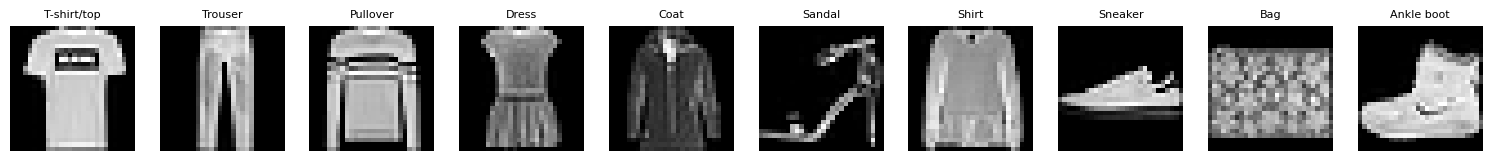

In [5]:
save_path_fashion = PROJECT_ROOT / "rapport/images"
show_fashion_examples(
    X_train_fashion,
    y_train_fashion,
    per_label=True,
    labels=list(range(10)),
    n_per_label=1,
    save_path=save_path_fashion / "fashion_examples_by_label.png",
)

In [ ]:
grid_size_fashion = (8, 8)

## **Fashion-MNIST - Pour Batch SOM**

In [6]:
batch_som_fashion = som.batchSOM(rayon_init=8.0, grid_size=grid_size_fashion, n_steps=250, dis_choice="euclidean", calculate_qe=True)
weights_som_fashion, history_som_fashion = batch_som_fashion.train(X_train_fashion)

results_som_fashion = eval_utils.evaluate_som_model(
    model_name="SOM",
    data=X_test_fashion,
    weights=weights_som_fashion,
    y_true=y_test_fashion,
    grid_size=grid_size_fashion,
    training_time=None
)
results_som_fashion

{'Modèle': 'SOM',
 'QE': np.float64(4.5308933843206125),
 'TE': 0.3985,
 'Pureté': np.float64(0.7115),
 'NMI': 0.5026970956723835,
 'Grille': '8x8'}

## **Fashion-MNIST - Pour AE + Batch SOM**

In [7]:
ae_som_model_fashion = ae_som.AESOM(
    input_dim=784,
    latent_dim=10,
    rayon_init=8.0,
    grid_size=grid_size_fashion,
    n_steps_som=250, 
    calculate_qe=True,
    weight_init="random",
    dis_choice="euclidean",
    topology="rectangular"
)

ae_losses_fashion, weights_ae_som_fashion_r = ae_som_model_fashion.train_ae_n_som(X_train_fashion)

Z_test_fashion = ae_som_model_fashion.encode_latent(X_test_fashion)

weights_ae_som_fashion, history_ae_som_fashion = weights_ae_som_fashion_r

results_ae_som_fashion = eval_utils.evaluate_som_model(
    model_name="AE+SOM",
    data=Z_test_fashion,
    weights=weights_ae_som_fashion,
    y_true=y_test_fashion,
    grid_size=grid_size_fashion,
    training_time=None
)
results_ae_som_fashion

{'Modèle': 'AE+SOM',
 'QE': np.float64(0.8869507378012454),
 'TE': 0.406,
 'Pureté': np.float64(0.722),
 'NMI': 0.5097775245203677,
 'Grille': '8x8'}

## **Fashion-MNIST - Pour DESOM**

In [8]:
desom_model_fashion = desom.DESOM(
    grid_size=grid_size_fashion,
    input_dim=784,
    latent_dim=10,
    n_epochs=100,
    batch_size=32,
    sigma_init=8.0,
    gamma=1e-3
)

desom_losses_fashion = desom_model_fashion.embedded_train(X_train_fashion)

Z_test_desom_fashion = desom_model_fashion.encode(X_test_fashion).detach().cpu().numpy()

weights_desom_fashion = desom_model_fashion.som.weights.detach().cpu().numpy()

results_desom_fashion = eval_utils.evaluate_som_model(
    model_name="DESOM",
    data=Z_test_desom_fashion,
    weights=weights_desom_fashion,
    y_true=y_test_fashion,
    grid_size=grid_size_fashion,
    training_time=None
)
results_desom_fashion

{'Modèle': 'DESOM',
 'QE': np.float64(0.17705680859457898),
 'TE': 0.5095,
 'Pureté': np.float64(0.7375),
 'NMI': 0.5162876933877901,
 'Grille': '8x8'}

## **Fashion-MNIST - Création de tableau**

In [9]:
list_results_fashion = [results_som_fashion, results_ae_som_fashion, results_desom_fashion]
df_results_fashion = eval_utils.create_results_dataframe_to_latex("resultats_des_metriques_fashion",list_results_fashion)

## **PROTOTYPE GRID**


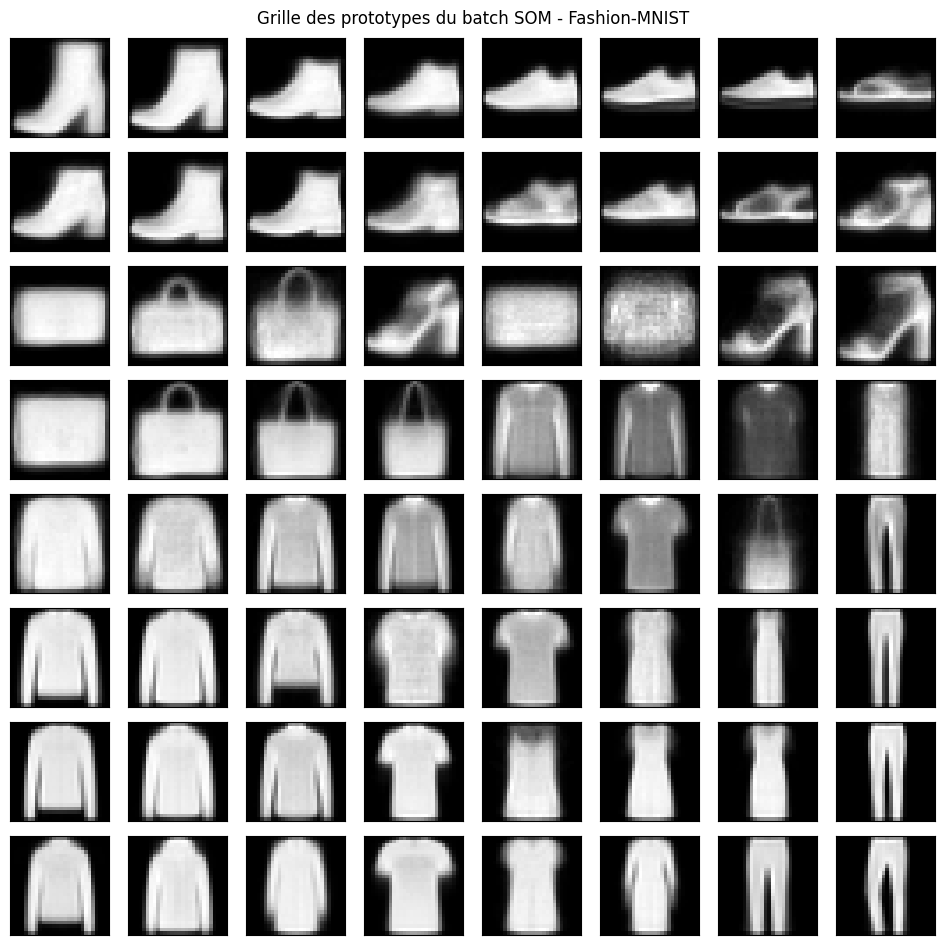

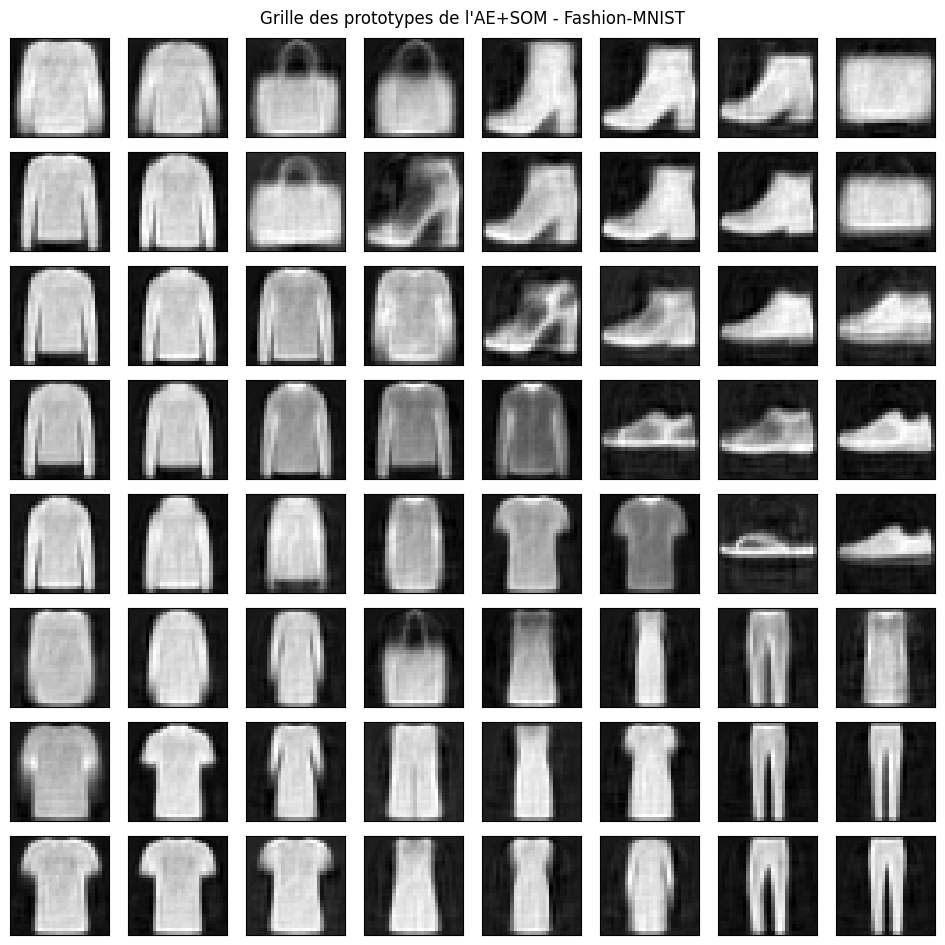

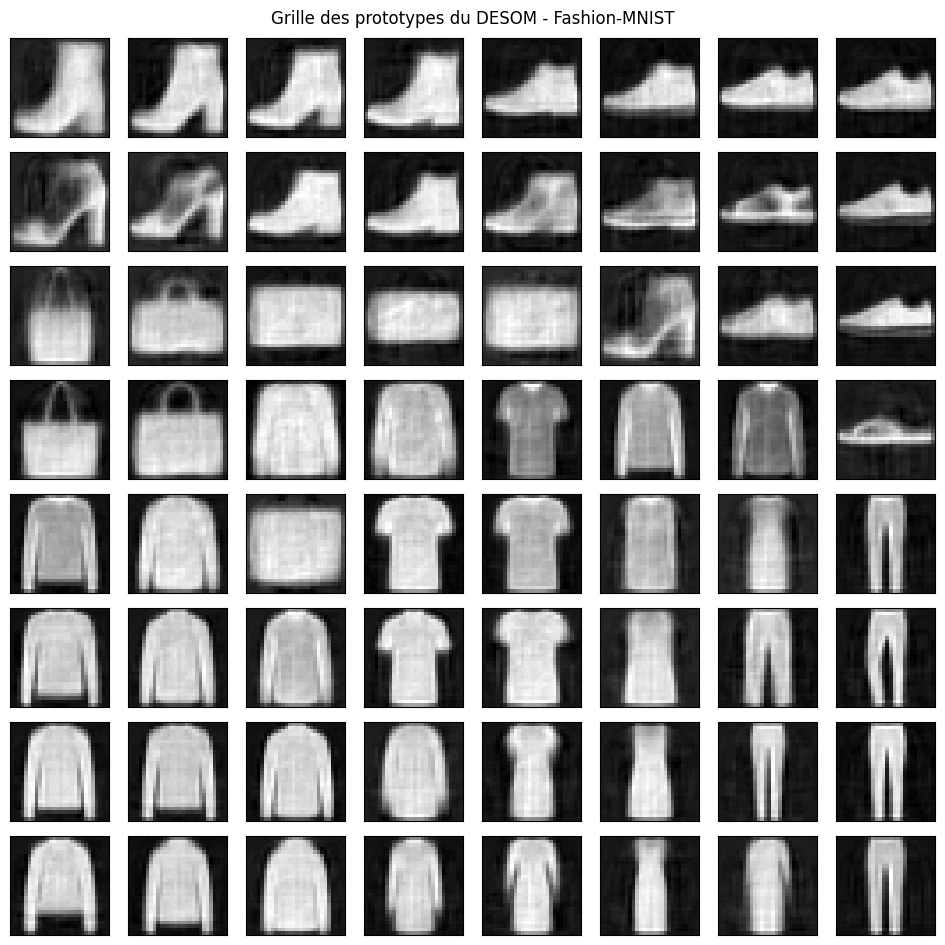

In [10]:
eval_utils.plot_prototype_grid(
    weights=weights_som_fashion,
    grid_size=grid_size_fashion,
    title="Grille des prototypes du batch SOM - Fashion-MNIST",
    save_path=save_path_fashion / "fashion_mnist_prototype_grid_som.png",
)

eval_utils.plot_prototype_grid(
    weights=weights_ae_som_fashion,
    grid_size=grid_size_fashion,
    title="Grille des prototypes de l'AE+SOM - Fashion-MNIST",
    decoder=ae_som_model_fashion.autoencoder.decodeur,
    save_path=save_path_fashion / "fashion_mnist_prototype_grid_ae_som.png",
)

eval_utils.plot_prototype_grid(
    weights=weights_desom_fashion,
    grid_size=grid_size_fashion,
    title="Grille des prototypes du DESOM - Fashion-MNIST",
    decoder=desom_model_fashion.ae.decodeur,
    save_path=save_path_fashion / "fashion_mnist_prototype_grid_desom.png",
)

## **Fashion-MNIST - U-matrices**

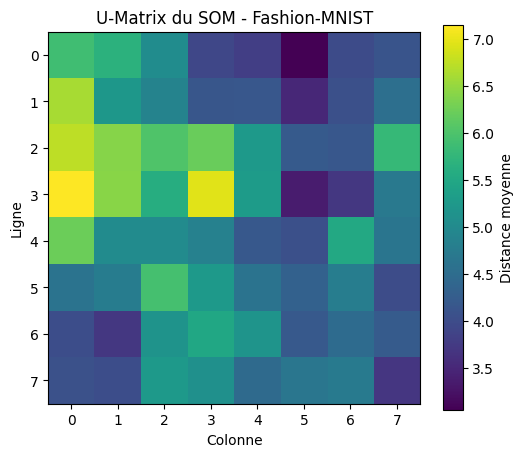

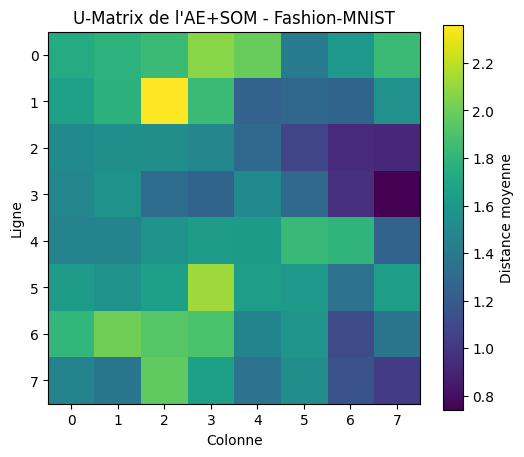

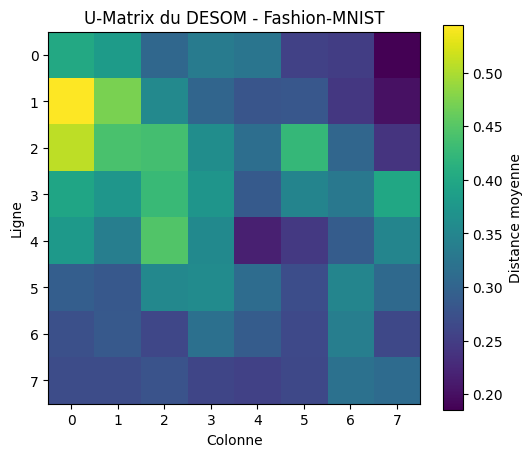

In [11]:
# batch SOM
f_umat_som = eval_utils.plot_u_matrix(weights_som_fashion, grid_size_fashion, title="U-Matrix du SOM - Fashion-MNIST", save_path=save_path_fashion / "u_matrix_som_fashion.png")

# AE+SOM
f_umat_ae_som = eval_utils.plot_u_matrix(weights_ae_som_fashion, grid_size_fashion, title="U-Matrix de l'AE+SOM - Fashion-MNIST", save_path=save_path_fashion / "u_matrix_ae_som_fashion.png")

# DESOM
f_umat_desom = eval_utils.plot_u_matrix(weights_desom_fashion, grid_size_fashion, title="U-Matrix du DESOM - Fashion-MNIST", save_path=save_path_fashion / "u_matrix_desom_fashion.png")

## **Fashion-MNIST - Hit maps**

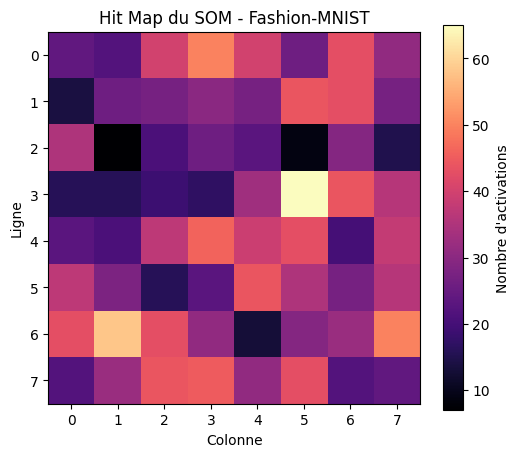

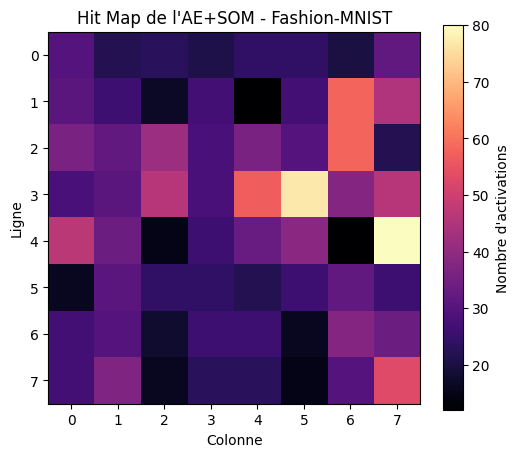

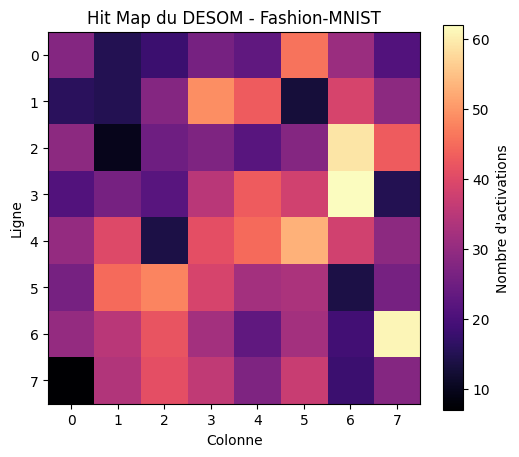

In [12]:
# batch SOM
eval_utils.hit_map(X_test_fashion, weights_som_fashion, grid_size_fashion, title="Hit Map du SOM - Fashion-MNIST", save_path=save_path_fashion / "hit_map_som_fashion.png")

# AE+SOM
eval_utils.hit_map(Z_test_fashion, weights_ae_som_fashion, grid_size_fashion, title="Hit Map de l'AE+SOM - Fashion-MNIST", save_path=save_path_fashion / "hit_map_ae_som_fashion.png")

# DESOM
eval_utils.hit_map(Z_test_desom_fashion, weights_desom_fashion, grid_size_fashion, title="Hit Map du DESOM - Fashion-MNIST", save_path=save_path_fashion / "hit_map_desom_fashion.png")

## **Carte des prototypes Fashion-MNIST**


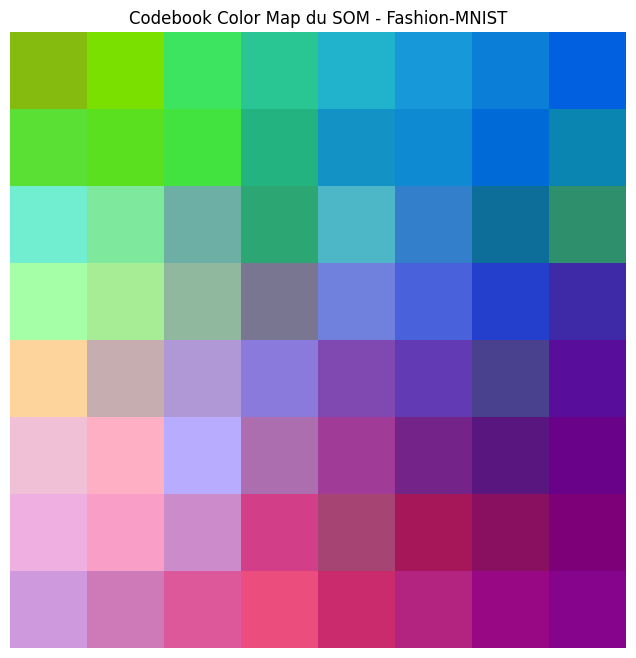

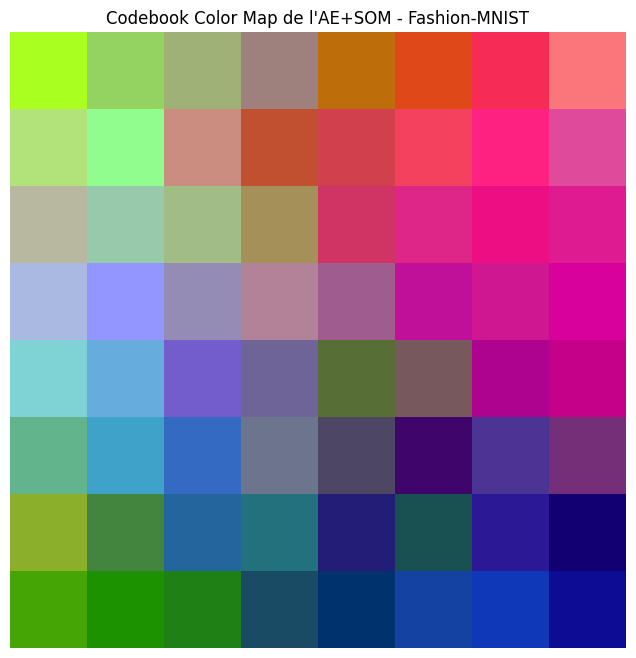

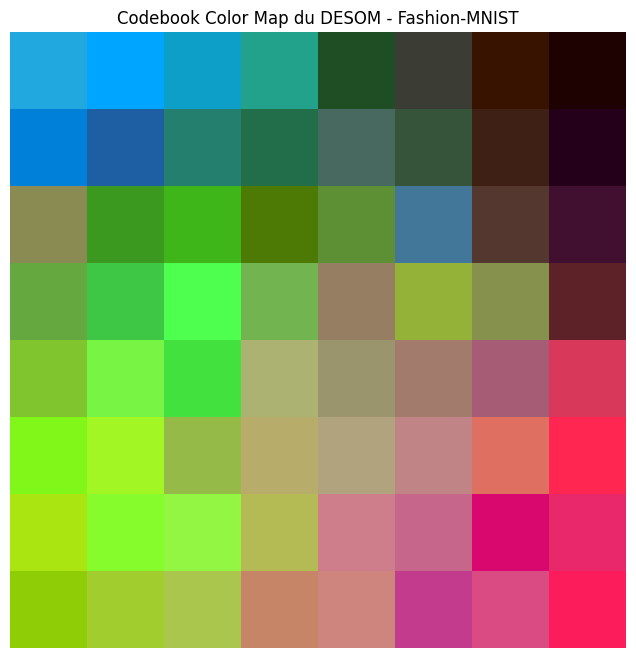

array([[[0.13023023, 0.6614843 , 0.873281  ],
        [0.        , 0.6506036 , 1.        ],
        [0.05824267, 0.62648237, 0.788046  ],
        [0.13581549, 0.6386448 , 0.5430281 ],
        [0.1229816 , 0.30330458, 0.14471528],
        [0.23431534, 0.24035405, 0.20998201],
        [0.22302257, 0.08166818, 0.        ],
        [0.11948995, 0.00410151, 0.00712903]],

       [[0.00309716, 0.505749  , 0.84974176],
        [0.117901  , 0.37217748, 0.6422017 ],
        [0.14141974, 0.5003332 , 0.4361868 ],
        [0.1376894 , 0.4315089 , 0.2937968 ],
        [0.28578362, 0.41337007, 0.37696284],
        [0.21351576, 0.33316818, 0.2293235 ],
        [0.2463191 , 0.12721734, 0.08158891],
        [0.14788601, 0.        , 0.10325459]],

       [[0.5390584 , 0.5467616 , 0.32834816],
        [0.23265819, 0.60050666, 0.12332965],
        [0.2455153 , 0.71202767, 0.09434959],
        [0.3056477 , 0.4780712 , 0.01968473],
        [0.36773774, 0.56088394, 0.20735799],
        [0.26128823, 0.4699916

In [13]:
eval_utils.plot_codebook_color_map(
    weights=weights_som_fashion,
    grid_size=grid_size_fashion,
    title="Codebook Color Map du SOM - Fashion-MNIST",
    save_path=save_path_fashion / "codebook_color_map_som_fashion.png"
)

eval_utils.plot_codebook_color_map(
    weights=weights_ae_som_fashion,
    grid_size=grid_size_fashion,
    title="Codebook Color Map de l'AE+SOM - Fashion-MNIST",
    save_path=save_path_fashion / "codebook_color_map_ae_som_fashion.png"
)

eval_utils.plot_codebook_color_map(
    weights=weights_desom_fashion,
    grid_size=grid_size_fashion,
    title="Codebook Color Map du DESOM - Fashion-MNIST",
    save_path=save_path_fashion / "codebook_color_map_desom_fashion.png"
)

## **Fashion-MNIST - Courbes d'apprentissage**

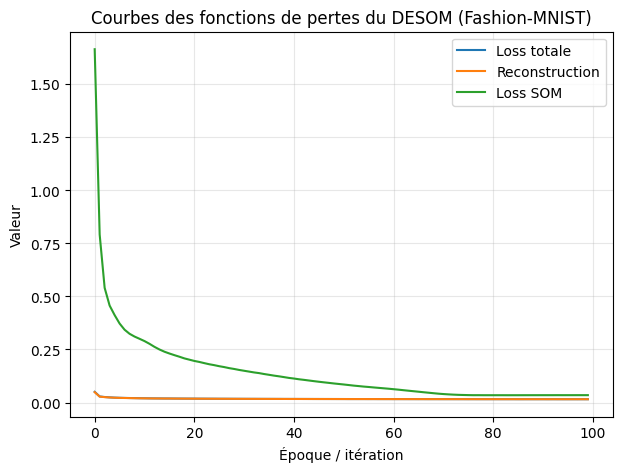

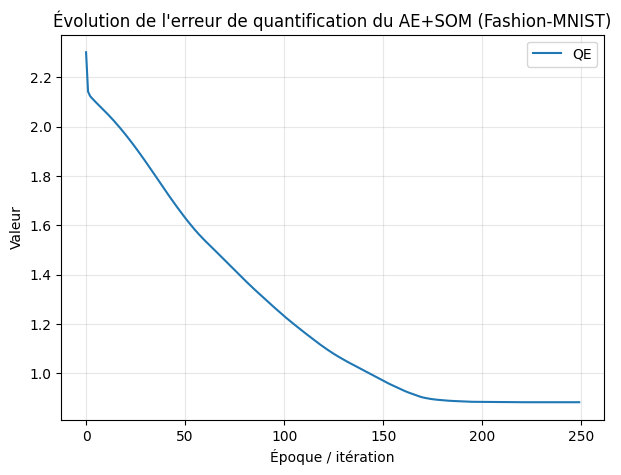

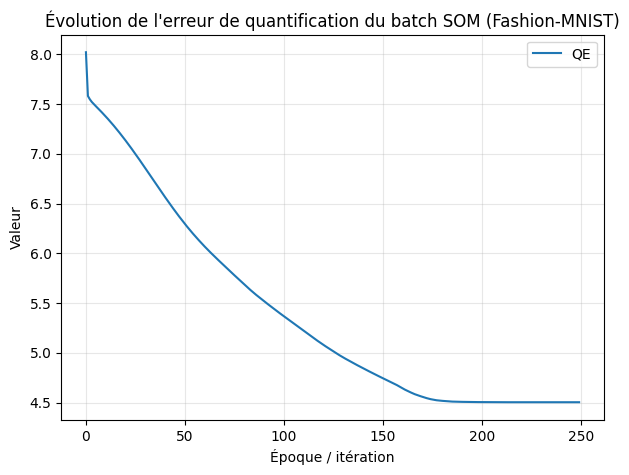

In [14]:
# DESOM
eval_utils.plot_training_curves(
    {
        "Loss totale": desom_losses_fashion["total"],
        "Reconstruction": desom_losses_fashion["reconstruction"],
        "Loss SOM": desom_losses_fashion["som"],
    },
    title="Courbes des fonctions de pertes du DESOM (Fashion-MNIST)",
    save_path=save_path_fashion / "training_curves_desom_fashion.png" 
)

# AE+SOM
eval_utils.plot_training_curves(
    {
        "QE": history_ae_som_fashion["QE"]
    },
    title="Évolution de l'erreur de quantification du AE+SOM (Fashion-MNIST)",
    save_path=save_path_fashion / "training_curves_ae_fashion.png" 
)

# batch SOM
eval_utils.plot_training_curves(
    history_som_fashion,
    title="Évolution de l'erreur de quantification du batch SOM (Fashion-MNIST)",
    save_path=save_path_fashion / "training_curves_som_fashion.png" 
)

## **Etude de la taille de grille avec Fashion MNIST** 

In [15]:
results_fashion_grid = []

rayon_init = 8.0

for gs in [(6, 6),(8, 8),(10, 10),(12, 12),(15, 15)]:


    print(f"Grille: {gs}, Rayon init: {rayon_init}")
    print("en cours...")

    # -----------------
    # Batch SOM
    # -----------------
    print("Entraînement du batch SOM...")
    batch_som_f = som.batchSOM(
        rayon_init=rayon_init,
        grid_size=gs,
        n_steps=250,
        dis_choice="euclidean",
        calculate_qe=False,
    )

    weights_som_f, history_som_f = batch_som_f.train(X_train_fashion)

    res_som_f = eval_utils.evaluate_som_model(
        model_name="SOM",
        data=X_test_fashion,
        weights=weights_som_f,
        y_true=y_test_fashion,
        grid_size=gs,
        training_time=None,
    )
    results_fashion_grid.append(res_som_f)

    # -----------------
    # AE + Batch SOM
    # -----------------
    print("Entraînement de l'AE+SOM...")
    ae_som_f = ae_som.AESOM(
        input_dim=784,
        latent_dim=10,
        rayon_init=rayon_init,
        grid_size=gs,
        n_steps_som=250,
        weight_init="random",
        dis_choice="euclidean",
        topology="rectangular",
    )

    ae_losses_f, weights_ae_som_f = ae_som_f.train_ae_n_som(X_train_fashion)

    Z_test_f = ae_som_f.encode_latent(X_test_fashion)   
    weights_ae_som_f, _ = weights_ae_som_f

    res_ae_f = eval_utils.evaluate_som_model(
        model_name="AE+SOM",
        data=Z_test_f,
        weights=weights_ae_som_f,
        y_true=y_test_fashion,
        grid_size=gs,
        training_time=None,
    )
    results_fashion_grid.append(res_ae_f)

    # -----------------
    # DESOM
    # -----------------
    print("Entraînement du DESOM...")
    desom_f = desom.DESOM(
        grid_size=gs,
        input_dim=784,
        latent_dim=10,
        n_epochs=100,
        batch_size=32,
        sigma_init=rayon_init,
        gamma=1e-3,
    )

    desom_losses_f = desom_f.embedded_train(X_train_fashion)

    Z_test_desom_f = desom_f.encode(X_test_fashion).detach().cpu().numpy()

    weights_desom_f = desom_f.som.weights.detach().cpu().numpy()

    res_desom_f = eval_utils.evaluate_som_model(
        model_name="DESOM",
        data=Z_test_desom_f,
        weights=weights_desom_f,
        y_true=y_test_fashion,
        grid_size=gs,
        training_time=None,
    )
    results_fashion_grid.append(res_desom_f)


df_results_fashion_grid = pd.DataFrame(results_fashion_grid)
df_results_fashion_grid["n_noeuds"] = df_results_fashion_grid["Grille"].apply(
    lambda s: int(s.split("x")[0]) * int(s.split("x")[1])
)


Grille: (6, 6), Rayon init: 8.0
en cours...
Entraînement du batch SOM...
Entraînement de l'AE+SOM...
Entraînement du DESOM...
Grille: (8, 8), Rayon init: 8.0
en cours...
Entraînement du batch SOM...
Entraînement de l'AE+SOM...
Entraînement du DESOM...
Grille: (10, 10), Rayon init: 8.0
en cours...
Entraînement du batch SOM...
Entraînement de l'AE+SOM...
Entraînement du DESOM...
Grille: (12, 12), Rayon init: 8.0
en cours...
Entraînement du batch SOM...
Entraînement de l'AE+SOM...
Entraînement du DESOM...
Grille: (15, 15), Rayon init: 8.0
en cours...
Entraînement du batch SOM...
Entraînement de l'AE+SOM...
Entraînement du DESOM...


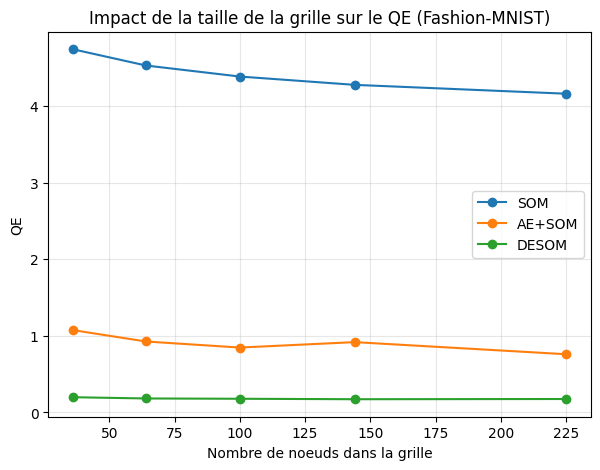

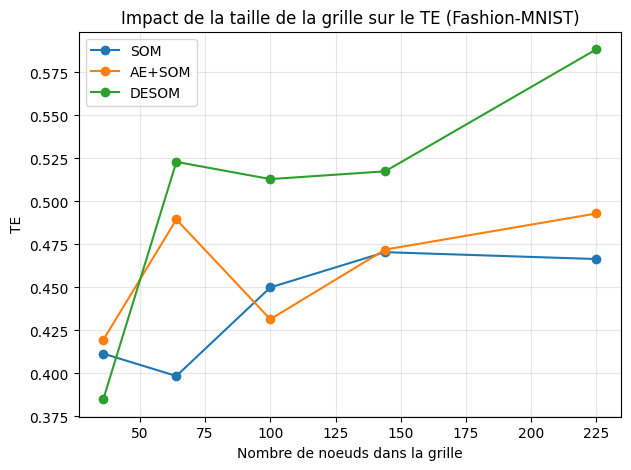

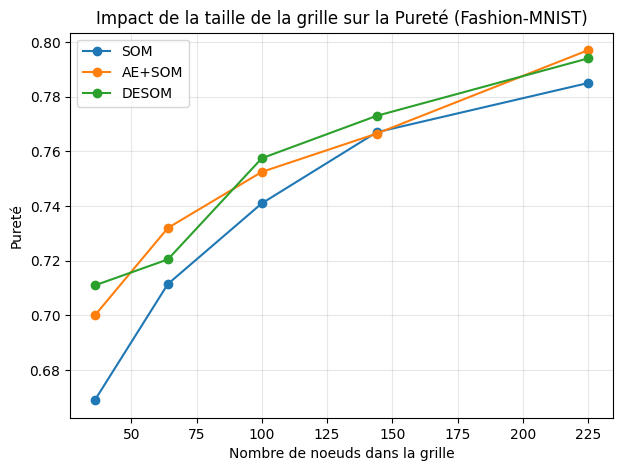

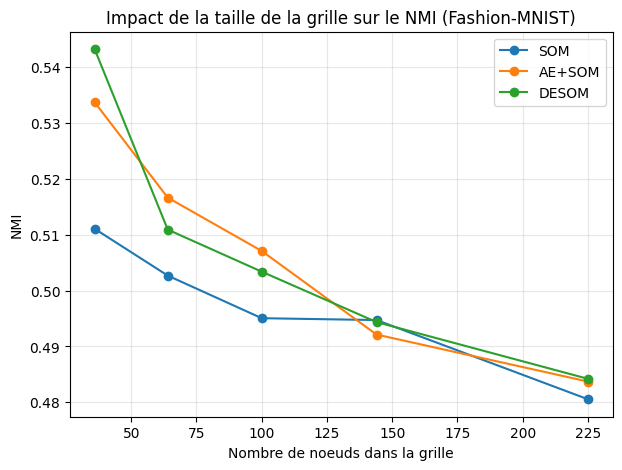

In [16]:
eval_utils.plot_grid_size_study(df_results_fashion_grid, metric="QE", title="Impact de la taille de la grille sur le QE (Fashion-MNIST)", save_path=save_path_fashion / "grid_size_study_qe_fashion.png")
eval_utils.plot_grid_size_study(df_results_fashion_grid, metric="TE", title="Impact de la taille de la grille sur le TE (Fashion-MNIST)", save_path=save_path_fashion / "grid_size_study_te_fashion.png")
eval_utils.plot_grid_size_study(df_results_fashion_grid, metric="Pureté", title="Impact de la taille de la grille sur la Pureté (Fashion-MNIST)", save_path=save_path_fashion / "grid_size_study_purete_fashion.png")
eval_utils.plot_grid_size_study(df_results_fashion_grid, metric="NMI", title="Impact de la taille de la grille sur le NMI (Fashion-MNIST)", save_path=save_path_fashion / "grid_size_study_nmi_fashion.png")